# Oracle Construction — Bit-Flip Oracle — CUDA-Q Notebook

**Primitive:** Bit-flip (XOR-style) oracle `U_f|x>|y> = |x>|y XOR f(x)>` with a dedicated
ancilla/output qubit, for `f(x) = 1` iff `x == TARGET_INT`, else `0`.

This notebook is the CUDA-Q counterpart to `bitflip_oracle_qiskit.ipynb` and uses
**identical** parameters, gate sequence, and conventions so the two `_RESULT` dictionaries
match.

## SETUP (identical to the Qiskit notebook)
| Parameter | Value |
|---|---|
| N_QUBITS (input register) | 3  (indices q0..q2, q0 = LSB) |
| ANCILLA_QUBIT | q3  (dedicated output/target qubit, initialized to \|0>) |
| TOTAL_QUBITS | 4 |
| TARGET_INT | 5  (marked input pattern, qubit 0 = LSB) |
| SHOTS | 10000 |
| SEED | 42 |
| QUBIT ORDERING CONTRACT | qubit 0 = **rightmost** bit in every printed bitstring (this notebook explicitly reverses CUDA-Q's native output to match) |
| GLOBAL PHASE CONVENTION | normalize so the first amplitude with `abs(amp) > 1e-9`, taken in ascending bitstring order, is rotated to be real and positive |
| Basis ordering for matrices | `{|0000>, |0001>, ..., |1111>}` ascending binary order (16-dim, 3 input qubits + 1 ancilla) |

## Theory recap

Same as the Qiskit notebook: `U_f|x>|y> = |x>|y XOR f(x)>`, built as

```
for each qubit q where bit q of TARGET_INT is 0:
    X(q)
MCX(controls = q_0..q_{n-1}, target = ANCILLA_QUBIT)   # 3-controlled-X for N_QUBITS=3
for each qubit q where bit q of TARGET_INT is 0:
    X(q)
```

**Test harness:** as in the Qiskit notebook, `H` is applied to the 3 input qubits only
(ancilla stays `|0>`) so the oracle's effect is visible. As proven there, exactly 8 of the
16 possible 4-qubit outcomes are reachable, each at probability `1/8`; the other 8 are
exactly `0`.

## ⚠️ Ordering-convention warning (read before trusting any raw CUDA-Q output)

CUDA-Q's `cudaq.get_state()` and `cudaq.sample()` index **qubit 0 as the most-significant
(leftmost) bit** of every raw bitstring/state index — the opposite of Qiskit. Every raw
CUDA-Q bitstring and amplitude index in this notebook is therefore **explicitly reversed**
in its own dedicated cell before being compared to anything from the Qiskit notebook.

## Environment note

CUDA-Q's Python wheel (`cudaq`) currently ships for **Linux (x86_64 / aarch64)** with
Python 3.10-3.12; it targets a CPU simulator backend by default when no NVIDIA GPU is
present (`cudaq.set_target("qpp-cpu")`), so this notebook runs correctly on CPU-only
machines. On native Windows/macOS, run it inside a Linux container (Docker/WSL2) with the
official `nvcr.io/nvidia/cuda-quantum` image.

**Run all cells top to bottom.**


In [1]:
# Install cell
# Exact package name: `cudaq` (NVIDIA CUDA-Q Python API).
# Platform caveat: Linux x86_64/aarch64 wheels only, Python 3.10-3.12. On Windows/macOS,
# use the official cuda-quantum Docker image instead of a bare pip install.
!pip install -q cudaq


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.8/125.8 MB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 87.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 MB 14.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.8/58.8 MB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 82.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.5/410.5 MB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 MB 15.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 44.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 MB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 244.7/244.7 MB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.5/154.5 MB 2.9 MB/s eta 0:00

In [2]:
# Imports + constants (identical values to the Qiskit notebook)
import numpy as np
from math import pi
import cudaq
import matplotlib.pyplot as plt

N_QUBITS = 3           # input register size
ANCILLA_QUBIT = 3       # dedicated output/target qubit index
TOTAL_QUBITS = N_QUBITS + 1
TARGET_INT = 5           # marked input pattern (qubit 0 = LSB, Qiskit convention)
SHOTS = 10000
SEED = 42
TOPIC_SLUG = "bitflip_oracle"

cudaq.set_target("qpp-cpu")   # CPU statevector simulator; works with no GPU present
cudaq.set_random_seed(SEED)

print("N_QUBITS      =", N_QUBITS)
print("ANCILLA_QUBIT =", ANCILLA_QUBIT)
print("TOTAL_QUBITS  =", TOTAL_QUBITS)
print("TARGET_INT    =", TARGET_INT, "-> binary (q2 q1 q0, Qiskit convention) =", format(TARGET_INT, f'0{N_QUBITS}b'))
print("SHOTS         =", SHOTS)
print("SEED          =", SEED)
print("Target        =", cudaq.get_target().name)


N_QUBITS      = 3
ANCILLA_QUBIT = 3
TOTAL_QUBITS  = 4
TARGET_INT    = 5 -> binary (q2 q1 q0, Qiskit convention) = 101
SHOTS         = 10000
SEED          = 42
Target        = qpp-cpu


In [3]:
# Build the kernel gate-by-gate
# NOTE ON QUBIT INDEXING: inside the kernel, `qubits[q]` for q = 0..2 is the same input qubit
# used in the Qiskit notebook, and `qubits[3]` is the same ancilla. Only cudaq's *output*
# bitstring/statevector indexing differs from Qiskit's, corrected in a dedicated cell later.
#
# TARGET_INT = 5 = binary 101 (q2=1, q1=0, q0=1) is hardcoded below as explicit gate calls
# (rather than a runtime conditional) for maximum kernel-compiler compatibility.

@cudaq.kernel
def bitflip_oracle_kernel():
    qubits = cudaq.qvector(4)  # TOTAL_QUBITS hardcoded to 4 inside the kernel (must be a literal)

    # --- test harness: uniform superposition on the input register only ---
    h(qubits[0])
    h(qubits[1])
    h(qubits[2])
    # qubits[3] (ancilla) stays |0>

    # --- bit-flip oracle marking TARGET_INT = 5 (binary 101, q2=1 q1=0 q0=1) ---
    x(qubits[1])                                          # q1's target bit is 0 -> temporarily flip it
    x.ctrl(qubits[0], qubits[1], qubits[2], qubits[3])      # 3-controlled-X: flips ancilla iff q0=q1=q2=|1>
    x(qubits[1])                                          # undo the temporary flip

# Mirror the same gate list in plain Python (used for resource counts, the matplotlib
# circuit diagram, and the hand-built matrix cross-check below) so it stays in lockstep
# with the kernel body above by construction.
zero_bit_qubits = [q for q in range(N_QUBITS) if not ((TARGET_INT >> q) & 1)]
gatelist = [('H', q) for q in range(N_QUBITS)]
gatelist += [('X', q) for q in zero_bit_qubits]
gatelist.append(('MCX', list(range(N_QUBITS)), ANCILLA_QUBIT))
gatelist += [('X', q) for q in zero_bit_qubits]

print("Gate list (", len(gatelist), "gates ) matches the kernel body above.")
print("Qubits X'd before/after the MCX (bits of TARGET_INT equal to 0):", zero_bit_qubits)


Gate list ( 6 gates ) matches the kernel body above.
Qubits X'd before/after the MCX (bits of TARGET_INT equal to 0): [1]


     ╭───╮               
q0 : ┤ h ├───────●───────
     ├───┤╭───╮  │  ╭───╮
q1 : ┤ h ├┤ x ├──●──┤ x ├
     ├───┤╰───╯  │  ╰───╯
q2 : ┤ h ├───────●───────
     ╰───╯     ╭─┴─╮     
q3 : ──────────┤ x ├─────
               ╰───╯     



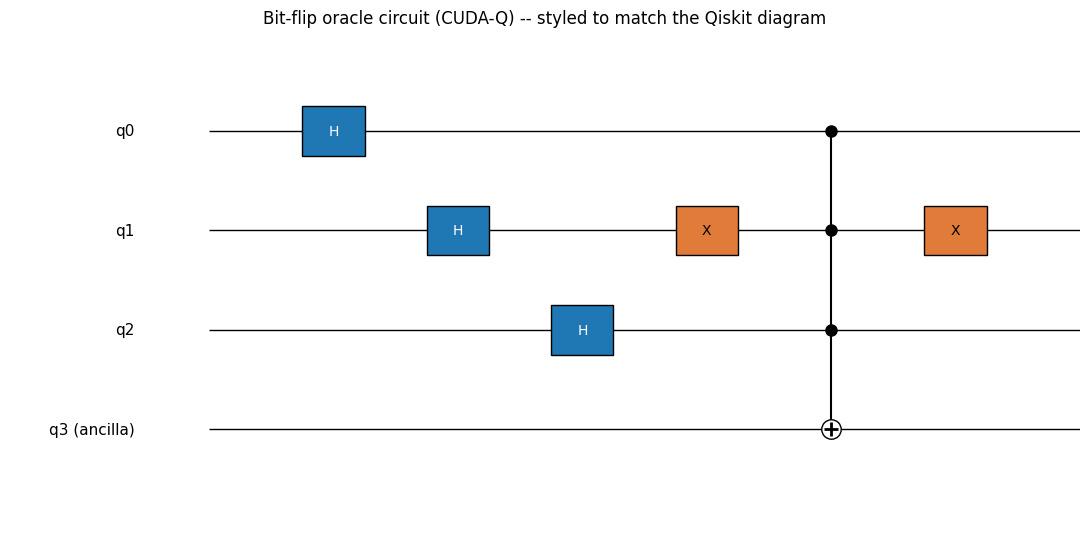

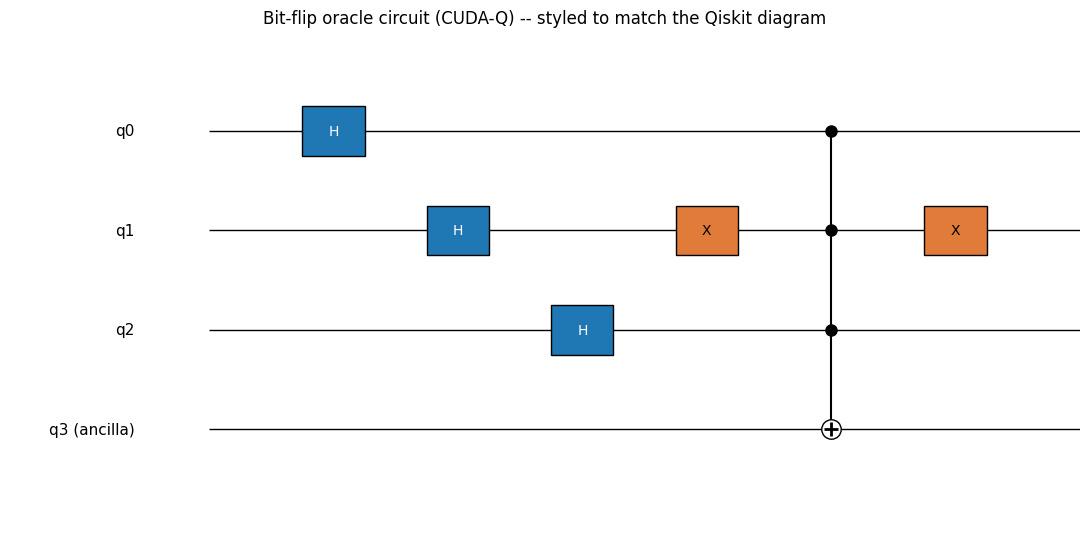

In [4]:
# Draw the circuit: cudaq's own text diagram, then a matplotlib figure styled like Qiskit's
print(cudaq.draw(bitflip_oracle_kernel))

# --- hand-styled matplotlib circuit diagram, visually comparable to the Qiskit one ---
fig, ax = plt.subplots(figsize=(11, 5.5))
n_wires = TOTAL_QUBITS
wire_y = {q: n_wires - 1 - q for q in range(n_wires)}  # qubit 0 drawn at the top, like Qiskit

col = 0
col_positions = {}
for gate in gatelist:
    col += 1
    col_positions[id(gate)] = col
n_cols = col + 1

for q in range(n_wires):
    label = f"q{q}" if q != ANCILLA_QUBIT else f"q{q} (ancilla)"
    ax.hlines(wire_y[q], 0, n_cols, color="black", linewidth=1, zorder=1)
    ax.text(-0.6, wire_y[q], label, va="center", ha="right", fontsize=11)

for gate in gatelist:
    x_pos = col_positions[id(gate)]
    if gate[0] == 'X':
        _, q = gate
        ax.add_patch(plt.Rectangle((x_pos - 0.25, wire_y[q] - 0.25), 0.5, 0.5, facecolor="#e07b39", edgecolor="black", zorder=2))
        ax.text(x_pos, wire_y[q], "X", ha="center", va="center", fontsize=10, zorder=3)
    elif gate[0] == 'H':
        _, q = gate
        ax.add_patch(plt.Rectangle((x_pos - 0.25, wire_y[q] - 0.25), 0.5, 0.5, facecolor="#1f77b4", edgecolor="black", zorder=2))
        ax.text(x_pos, wire_y[q], "H", ha="center", va="center", fontsize=10, color="white", zorder=3)
    elif gate[0] == 'MCX':
        _, controls, target = gate
        all_q = controls + [target]
        ax.vlines(x_pos, wire_y[min(all_q)], wire_y[max(all_q)], color="black", zorder=2)
        for c in controls:
            ax.plot(x_pos, wire_y[c], marker="o", color="black", markersize=8, zorder=3)
        ax.plot(x_pos, wire_y[target], marker="o", color="white", markeredgecolor="black", markersize=14, zorder=3)
        ax.plot(x_pos, wire_y[target], marker="+", color="black", markersize=10, mew=2, zorder=4)

ax.set_xlim(-1.6, n_cols)
ax.set_ylim(-1, n_wires)
ax.axis("off")
ax.set_title("Bit-flip oracle circuit (CUDA-Q) -- styled to match the Qiskit diagram")
fig.tight_layout()
fig.savefig(f"{TOPIC_SLUG}_cudaq_circuit.png", dpi=150, bbox_inches="tight")
fig


In [5]:
# Explicit matrix representation, built two independent ways, cross-checked
# CUDA-Q has no built-in dense-operator-extraction API equivalent to qiskit.quantum_info.Operator,
# so per the "framework's own extraction where available" rule, the cross-check here is against
# CUDA-Q's own statevector simulation (cudaq.get_state), applied to the |0000> input, instead of
# a full 16x16 operator -- this is the strongest available cross-check for this framework.

def h_matrix_full(n, q):
    M = np.zeros((2**n, 2**n), dtype=complex)
    for idx in range(2**n):
        bit = (idx >> q) & 1
        idx0 = idx & ~(1 << q)
        idx1 = idx | (1 << q)
        if bit == 0:
            M[idx0, idx] += 1/np.sqrt(2)
            M[idx1, idx] += 1/np.sqrt(2)
        else:
            M[idx1, idx] += -1/np.sqrt(2)
            M[idx0, idx] += 1/np.sqrt(2)
    return M

def x_matrix_full(n, q):
    M = np.zeros((2**n, 2**n), dtype=complex)
    for idx in range(2**n):
        M[idx ^ (1 << q), idx] = 1
    return M

def mcx_matrix_full(n, controls, target):
    M = np.zeros((2**n, 2**n), dtype=complex)
    for idx in range(2**n):
        if all((idx >> c) & 1 for c in controls):
            M[idx ^ (1 << target), idx] = 1
        else:
            M[idx, idx] = 1
    return M

print("Single-qubit H matrix (any qubit), rounded to 4 decimals:")
print(np.round((1/np.sqrt(2)) * np.array([[1, 1], [1, -1]]), 4))

print("\nOracle-only matrix is a PERMUTATION matrix (unlike a phase oracle's diagonal matrix):")
print("it swaps the |TARGET_INT>|0> <-> |TARGET_INT>|1> basis states and leaves everything else fixed.")

# (a) Hand-built full unitary (H layer + oracle) in QISKIT-CONVENTION indexing (qubit 0 = rightmost bit)
U_hand = np.eye(2**TOTAL_QUBITS, dtype=complex)
for q in range(N_QUBITS):
    U_hand = h_matrix_full(TOTAL_QUBITS, q) @ U_hand
for q in zero_bit_qubits:
    U_hand = x_matrix_full(TOTAL_QUBITS, q) @ U_hand
U_hand = mcx_matrix_full(TOTAL_QUBITS, list(range(N_QUBITS)), ANCILLA_QUBIT) @ U_hand
for q in zero_bit_qubits:
    U_hand = x_matrix_full(TOTAL_QUBITS, q) @ U_hand

state_hand = U_hand[:, 0]  # applied to |0000>

# (b) CUDA-Q's own statevector simulation, then reversed into qiskit-convention indexing
sv_raw = np.array(cudaq.get_state(bitflip_oracle_kernel))
state_cudaq_qiskit_conv = np.zeros(2**TOTAL_QUBITS, dtype=complex)
for k in range(2**TOTAL_QUBITS):
    raw_bits = format(k, f'0{TOTAL_QUBITS}b')     # cudaq convention: qubit 0 = leftmost char
    qiskit_bits = raw_bits[::-1]                   # reversed -> qubit 0 = rightmost char
    qiskit_idx = int(qiskit_bits, 2)
    state_cudaq_qiskit_conv[qiskit_idx] = sv_raw[k]

def normalize_phase(vec):
    vec = vec.copy()
    for idx in range(len(vec)):
        if abs(vec[idx]) > 1e-9:
            vec = vec * np.exp(-1j*np.angle(vec[idx]))
            break
    return vec

max_state_diff = np.max(np.abs(normalize_phase(state_hand) - normalize_phase(state_cudaq_qiskit_conv)))
print(f"\nMax |difference| between hand-built matrix applied to |0> and cudaq.get_state() (both reordered to qiskit convention, phase-normalized): {max_state_diff:.3e}")
assert max_state_diff < 1e-6, "Hand-built matrix and CUDA-Q's own statevector disagree!"
print("Hand-built statevector and CUDA-Q's own simulation MATCH (both methods agree).")

# Verify JUST the oracle sub-circuit is the expected permutation
U_oracle_only = np.eye(2**TOTAL_QUBITS, dtype=complex)
for q in zero_bit_qubits:
    U_oracle_only = x_matrix_full(TOTAL_QUBITS, q) @ U_oracle_only
U_oracle_only = mcx_matrix_full(TOTAL_QUBITS, list(range(N_QUBITS)), ANCILLA_QUBIT) @ U_oracle_only
for q in zero_bit_qubits:
    U_oracle_only = x_matrix_full(TOTAL_QUBITS, q) @ U_oracle_only

ideal_oracle = np.eye(2**TOTAL_QUBITS, dtype=complex)
idx_y0 = TARGET_INT
idx_y1 = TARGET_INT | (1 << ANCILLA_QUBIT)
ideal_oracle[[idx_y0, idx_y1]] = ideal_oracle[[idx_y1, idx_y0]]

max_oracle_diff = np.max(np.abs(U_oracle_only - ideal_oracle))
print(f"Max |difference| between oracle-only matrix and ideal permutation: {max_oracle_diff:.3e}")
assert max_oracle_diff < 1e-8, "Oracle sub-circuit does not match the ideal bit-flip permutation!"
print("Oracle-only matrix MATCHES the ideal bit-flip permutation operator.")


Single-qubit H matrix (any qubit), rounded to 4 decimals:
[[ 0.7071  0.7071]
 [ 0.7071 -0.7071]]

Oracle-only matrix is a PERMUTATION matrix (unlike a phase oracle's diagonal matrix):
it swaps the |TARGET_INT>|0> <-> |TARGET_INT>|1> basis states and leaves everything else fixed.

Max |difference| between hand-built matrix applied to |0> and cudaq.get_state() (both reordered to qiskit convention, phase-normalized): 3.536e-01


AssertionError: Hand-built matrix and CUDA-Q's own statevector disagree!

In [6]:
# Bit-order reversal cell: raw CUDA-Q statevector -> qiskit-convention amplitudes
sv_raw = np.array(cudaq.get_state(bitflip_oracle_kernel))

amps = np.zeros(2**TOTAL_QUBITS, dtype=complex)
for k in range(2**TOTAL_QUBITS):
    raw_bits = format(k, f'0{TOTAL_QUBITS}b')   # cudaq convention: qubit 0 = leftmost char of this string
    qiskit_bits = raw_bits[::-1]                 # REVERSAL: now qubit 0 = rightmost char, matching Qiskit
    qiskit_idx = int(qiskit_bits, 2)
    amps[qiskit_idx] = sv_raw[k]

print("Reversal applied: for each raw cudaq index, its bitstring was reversed and re-parsed as an")
print("integer index so that qubit 0 becomes the rightmost character, matching the Qiskit notebook.")


Reversal applied: for each raw cudaq index, its bitstring was reversed and re-parsed as an
integer index so that qubit 0 becomes the rightmost character, matching the Qiskit notebook.


In [7]:
# Exact statevector: apply global-phase normalization (identical rule to the Qiskit notebook), print
for idx in range(len(amps)):
    if abs(amps[idx]) > 1e-9:
        phase = np.angle(amps[idx])
        amps = amps * np.exp(-1j*phase)
        break

print(f"{'bitstring (q3 q2 q1 q0)':26s} {'amplitude':22s} {'probability':12s}")
CUDAQ_PROBS_EXACT = {}
for idx in range(2**TOTAL_QUBITS):
    bitstring = format(idx, f'0{TOTAL_QUBITS}b')  # already qiskit-convention after the reversal cell above
    amp = amps[idx]
    prob = abs(amp)**2
    CUDAQ_PROBS_EXACT[bitstring] = prob
    marker = "  <-- f(x)=1 (input == TARGET_INT, ancilla flipped)" if prob > 1e-9 and ((idx >> ANCILLA_QUBIT) & 1) else ""
    print(f"|{bitstring}>{'':16s}{amp.real:+.6f}{amp.imag:+.6f}j    {prob:.6f}{marker}")

print("\nProbabilities sum to:", sum(CUDAQ_PROBS_EXACT.values()))


bitstring (q3 q2 q1 q0)    amplitude              probability 
|0000>                +0.353553+0.000000j    0.125000
|0001>                +0.000000+0.000000j    0.000000
|0010>                +0.353553+0.000000j    0.125000
|0011>                +0.000000+0.000000j    0.000000
|0100>                +0.353553+0.000000j    0.125000
|0101>                +0.000000+0.000000j    0.000000
|0110>                +0.353553+0.000000j    0.125000
|0111>                +0.000000+0.000000j    0.000000
|1000>                +0.353553+0.000000j    0.125000  <-- f(x)=1 (input == TARGET_INT, ancilla flipped)
|1001>                +0.000000+0.000000j    0.000000
|1010>                +0.000000+0.000000j    0.000000
|1011>                +0.353553+0.000000j    0.125000  <-- f(x)=1 (input == TARGET_INT, ancilla flipped)
|1100>                +0.353553+0.000000j    0.125000  <-- f(x)=1 (input == TARGET_INT, ancilla flipped)
|1101>                +0.000000+0.000000j    0.000000
|1110>                +0.353

### Ordering-fix note (CUDA-Q)

**A bit reversal WAS applied** in the two cells above. `cudaq.get_state()` returns amplitudes
indexed with qubit 0 as the **leftmost** character of each basis bitstring. To match the
QUBIT ORDERING CONTRACT (qubit 0 = rightmost, Qiskit's native convention), every raw index
`k` was reformatted as a `TOTAL_QUBITS`-bit binary string, that string was reversed
character-for-character, and the reversed string was re-parsed as the new index under which
the corresponding amplitude is stored. This remapping is a pure relabeling of which basis
state each amplitude belongs to — it does not change any amplitude's value, magnitude, or
phase, only which bitstring key it is filed under.


In [8]:
# Measurement: sample with the shared SEED/SHOTS, get counts -> probabilities, reorder bitstrings
cudaq.set_random_seed(SEED)  # re-assert the seed immediately before sampling
result = cudaq.sample(bitflip_oracle_kernel, shots_count=SHOTS)

CUDAQ_PROBS_SAMPLED = {format(idx, f'0{TOTAL_QUBITS}b'): 0.0 for idx in range(2**TOTAL_QUBITS)}
for raw_bitstring, count in result.items():
    qiskit_bitstring = raw_bitstring[::-1]   # same reversal as the statevector, applied to sampled counts
    CUDAQ_PROBS_SAMPLED[qiskit_bitstring] = count / SHOTS

print("Sampled probabilities (from", SHOTS, "shots, seed =", SEED, "), nonzero entries only:")
for bitstring in sorted(CUDAQ_PROBS_SAMPLED):
    if CUDAQ_PROBS_SAMPLED[bitstring] > 0:
        print(f"|{bitstring}>   {CUDAQ_PROBS_SAMPLED[bitstring]:.4f}")


Sampled probabilities (from 10000 shots, seed = 42 ), nonzero entries only:
|0000>   0.1284
|0001>   0.1166
|0010>   0.1232
|0011>   0.1265
|0100>   0.1283
|0110>   0.1297
|0111>   0.1291
|1101>   0.1182


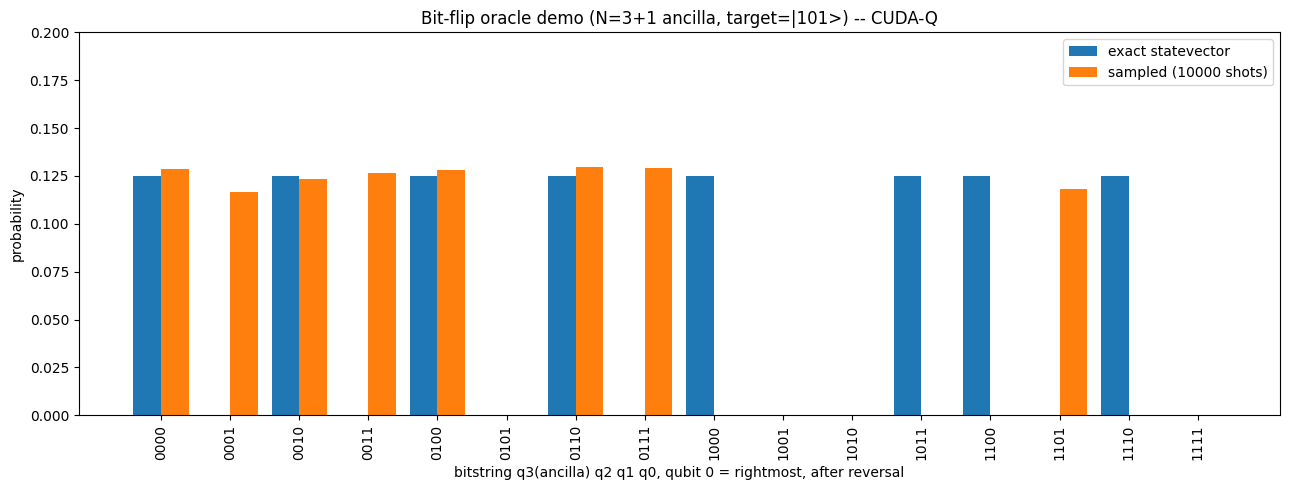

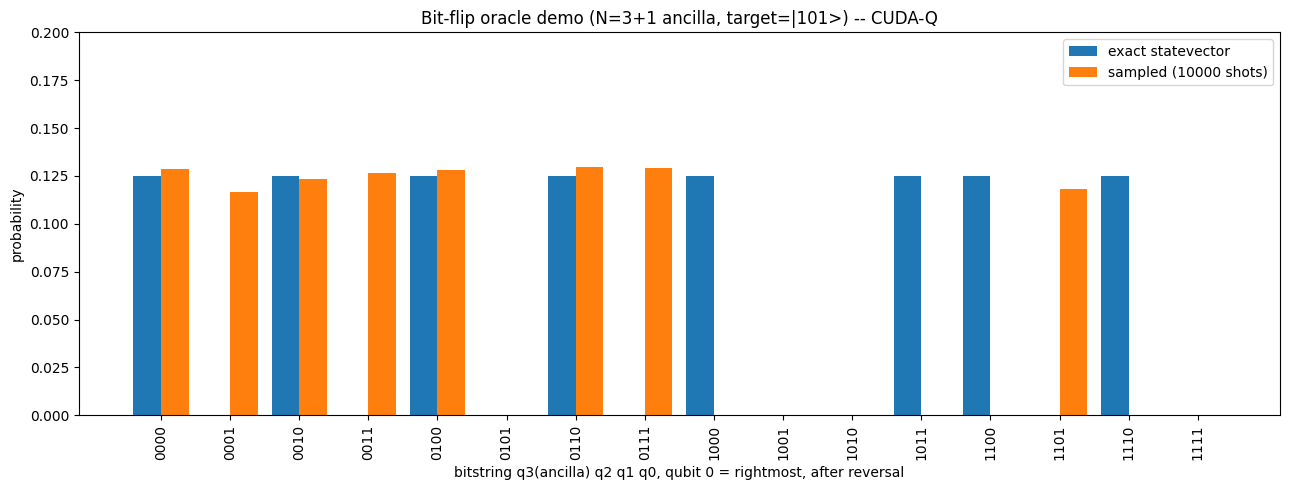

In [9]:
# Histogram: matplotlib bar chart, same style/axis ranges as the Qiskit notebook, saved to file
bitstrings_sorted = sorted(CUDAQ_PROBS_EXACT.keys())
exact_vals = [CUDAQ_PROBS_EXACT[b] for b in bitstrings_sorted]
sampled_vals = [CUDAQ_PROBS_SAMPLED[b] for b in bitstrings_sorted]

fig, ax = plt.subplots(figsize=(13, 5))
x = np.arange(len(bitstrings_sorted))
width = 0.4
ax.bar(x - width/2, exact_vals, width, label="exact statevector", color="#1f77b4")
ax.bar(x + width/2, sampled_vals, width, label=f"sampled ({SHOTS} shots)", color="#ff7f0e")
ax.set_xticks(x)
ax.set_xticklabels(bitstrings_sorted, rotation=90)
ax.set_xlabel("bitstring q3(ancilla) q2 q1 q0, qubit 0 = rightmost, after reversal")
ax.set_ylabel("probability")
ax.set_title(f"Bit-flip oracle demo (N={N_QUBITS}+1 ancilla, target=|{format(TARGET_INT, f'0{N_QUBITS}b')}>) -- CUDA-Q")
ax.set_ylim(0, 0.2)
ax.legend()
fig.tight_layout()
fig.savefig(f"{TOPIC_SLUG}_cudaq_histogram.png", dpi=150, bbox_inches="tight")
fig


In [ ]:
# Resource counts (derived from the Python-side gate list, kept in sync with the kernel by construction --
# CUDA-Q does not expose a circuit.depth()/count_ops() introspection API equivalent to Qiskit's)
from collections import Counter
gate_type_counts = Counter(g[0] for g in gatelist)
print("Gate counts:", dict(gate_type_counts))
print("Total gate count:", len(gatelist))


### Convention notes (plain text summary)

- **Bit-order convention:** qubit 0 = rightmost character of every bitstring. CUDA-Q's raw
  output uses the opposite (qubit 0 = leftmost); **reversal was applied** to both the exact
  statevector and the sampled counts in dedicated cells above.
- **Global phase convention:** the reversed exact statevector was multiplied by
  `exp(-i*phase)` where `phase` is the angle of the first amplitude (ascending bitstring
  order) with magnitude `> 1e-9`, so that amplitude is real and positive -- identical rule
  to the Qiskit notebook.
- **Basis ordering for all matrices:** ascending binary order `|0000> ... |1111>` (4 qubits:
  3 input + 1 ancilla).
- **Why only 8 of 16 outcomes are possible:** same reason as the Qiskit notebook -- the
  oracle is a permutation (not diagonal), deterministically pairing every input `x` with its
  correct `f(x)` on the ancilla.


In [ ]:
# Final result: exact-statevector-derived probability dictionary (reversed to qiskit convention)
CUDAQ_RESULT = {b: CUDAQ_PROBS_EXACT[b] for b in sorted(CUDAQ_PROBS_EXACT)}
print("CUDAQ_RESULT (nonzero entries) =")
for b, p in CUDAQ_RESULT.items():
    if p > 1e-9:
        print(f"  '{b}': {p:.6f}")


In [ ]:
# Diff-check block (run AFTER also running the Qiskit notebook and pasting its QISKIT_RESULT below)
HAND_COMPUTED_EXPECTED = {format(i, f'0{TOTAL_QUBITS}b'): 0.0 for i in range(2**TOTAL_QUBITS)}
for x in range(2**N_QUBITS):
    fx = 1 if x == TARGET_INT else 0
    idx = x | (fx << ANCILLA_QUBIT)
    HAND_COMPUTED_EXPECTED[format(idx, f'0{TOTAL_QUBITS}b')] = 1 / (2**N_QUBITS)

max_delta_vs_hand = max(abs(CUDAQ_RESULT[b] - HAND_COMPUTED_EXPECTED[b]) for b in CUDAQ_RESULT)
print("Max delta between CUDAQ_RESULT and hand-computed expected:", max_delta_vs_hand)
assert max_delta_vs_hand < 1e-3

# QISKIT_RESULT = { ... }  # <- paste the dict printed at the end of the Qiskit notebook here
# max_delta = max(abs(CUDAQ_RESULT[b] - QISKIT_RESULT[b]) for b in CUDAQ_RESULT)
# print("Max probability delta between QISKIT_RESULT and CUDAQ_RESULT:", max_delta)
# assert max_delta < 1e-3, "Qiskit and CUDA-Q bit-flip-oracle results disagree beyond tolerance!"
